# Cinco maiores municípios de MG e Lavras

E1 usa toda a rede sem capacidade. E2 usa toda a rede e capacidades hipotéticas. Todos os setores permanecem. Não existe seleção de escolas. A formulação usa PuLP com Gurobi e mantém o mesmo modelo da análise anterior.

In [1]:
from pathlib import Path
from time import perf_counter
import gc
import hashlib
import json
import numpy as np
import pandas as pd
import pulp
import gurobipy as gp
from IPython.display import display
raiz = Path.cwd()
if raiz.name == "src":
    raiz = raiz.parent
saida = raiz / "outputs/grandes_municipios"
resumo = pd.read_csv(saida / "resumo_instancias.csv", dtype={"codigo": "string"})

In [2]:
limite_tempo_s = 60
threads = 2
limite_memoria_gb = 3.0
fatores = [1.0, 1.25, 1.5]
retomar = True
campos = {"fundamental_iniciais": "QT_MAT_FUND_AI", "fundamental_finais": "QT_MAT_FUND_AF",
          "medio": "QT_MAT_MED_PROP"}
nomes_status = {2: "OPTIMAL", 3: "INFEASIBLE", 4: "INF_OR_UNBD", 9: "TIME_LIMIT", 17: "MEM_LIMIT"}
configuracao = {"limite_tempo_s": limite_tempo_s, "threads": threads,
                "memoria_gb": limite_memoria_gb, "gap_solicitado": 0.0, "seed": 1,
                "pulp": pulp.__version__, "gurobi": list(gp.gurobi.version())}
(saida / "parametros_solver.json").write_text(json.dumps(configuracao, indent=2))

Out[2]: 160


## Leitura e identificação das instâncias

A assinatura dos arquivos permite retomar apenas execuções com os mesmos dados e parâmetros. Casos com coordenadas pendentes ficam identificados e não usam escolas removidas.

In [3]:
def ler_instancia(linha):
    pasta = saida / "instancias" / linha.codigo / linha.etapa
    demanda = pd.read_csv(pasta / "demanda.csv", dtype={"CD_SETOR": "string"})
    escolas = pd.read_csv(pasta / "escolas.csv", dtype={"CO_ENTIDADE": "string"})
    w = demanda.set_index("CD_SETOR").demanda_inteira
    porte = escolas.set_index("CO_ENTIDADE")[campos[linha.etapa]]
    caminho = pasta / "distancias_km.csv"
    if linha.coordenadas_pendentes or not caminho.exists():
        return w, porte, None
    D = pd.read_csv(caminho, dtype={"CD_SETOR": "string"}).set_index("CD_SETOR")
    assert set(D.index) == set(w.index) and set(D.columns) == set(porte.index)
    D = D.reindex(index=w.index, columns=porte.index)
    assert len(w) == linha.setores and int(w.sum()) == linha.demanda
    assert np.isfinite(D.to_numpy()).all() and D.ge(0).all().all()
    return w, porte, D

In [4]:
def assinatura(linha):
    pasta = saida / "instancias" / linha.codigo / linha.etapa
    h = hashlib.sha256(json.dumps(configuracao, sort_keys=True).encode())
    for nome in ["demanda.csv", "escolas.csv", "distancias_km.csv"]:
        caminho = pasta / nome
        if caminho.exists():
            with caminho.open("rb") as arq:
                for bloco in iter(lambda: arq.read(1048576), b""):
                    h.update(bloco)
    return h.hexdigest()

def finito(valor):
    return float(valor) if np.isfinite(valor) else None

## Modelo de alocação capacitada

Cada variável representa um par setor e escola. A lista por linhas evita manter uma segunda estrutura grande de índices. Isso altera a organização do código, não as variáveis nem as restrições matemáticas.

In [5]:
def construir_modelo(w, Q, D):
    n, m = D.shape
    modelo = pulp.LpProblem("alocacao_rede_completa", pulp.LpMinimize)
    x = [pulp.LpVariable(f"x{k}", cat="Binary") for k in range(n * m)]
    pesos = w.to_numpy(dtype=int)
    custos = (D.to_numpy() * pesos[:, None]).ravel()
    modelo += pulp.LpAffineExpression(zip(x, custos))
    for i in range(n):
        modelo += pulp.lpSum(x[i * m:(i + 1) * m]) == 1
    for j, q in enumerate(Q):
        termos = ((x[i * m + j], int(pesos[i])) for i in range(n) if pesos[i])
        modelo += pulp.LpAffineExpression(termos) <= int(q)
    assert modelo.numVariables() == n * m and modelo.numConstraints() == n + m
    return modelo, x

In [6]:
def validar_e_salvar(destinos, w, Q, D, registro, pasta, capacitado=True):
    distancia = D.to_numpy()[np.arange(len(w)), destinos]
    tabela = pd.DataFrame({"CD_SETOR": w.index, "CO_ENTIDADE": Q.index[destinos],
                           "demanda": w.to_numpy(), "distancia_km": distancia})
    assert tabela.CD_SETOR.is_unique and set(tabela.CD_SETOR) == set(w.index)
    carga = np.bincount(destinos, weights=w.to_numpy(), minlength=len(Q))
    if capacitado:
        assert (carga <= Q.to_numpy() + 1e-5).all()
    custo = float(np.dot(w.to_numpy(), distancia))
    assert np.isclose(custo, registro["objetivo"], rtol=1e-7, atol=1e-4)
    tabela.to_csv(pasta / "atribuicoes.csv", index=False)
    uso = pd.DataFrame({"CO_ENTIDADE": Q.index, "capacidade": Q.values, "demanda_atribuida": carga})
    uso.to_csv(pasta / "utilizacao.csv", index=False)
    registro["distancia_media_km"] = custo / w.sum()

In [7]:
def resolver_e1(w, porte, D, registro, pasta):
    inicio = perf_counter()
    destinos = D.to_numpy().argmin(axis=1)
    objetivo = float(np.dot(w.to_numpy(), D.to_numpy()[np.arange(len(w)), destinos]))
    registro.update(status="OTIMO_ANALITICO", solucao_viavel=True, objetivo=objetivo,
                    limite_inferior=objetivo, gap=0.0, tempo_analitico_s=perf_counter() - inicio)
    validar_e_salvar(destinos, w, porte, D, registro, pasta, capacitado=False)

def extrair_motor(motor, registro):
    registro.update(status=nomes_status.get(motor.Status, str(motor.Status)),
                    solucao_viavel=motor.SolCount > 0, limite_inferior=finito(motor.ObjBound),
                    tempo_solver_s=motor.Runtime, nos=int(motor.NodeCount),
                    variaveis=motor.NumVars, restricoes=motor.NumConstrs)
    if motor.SolCount:
        registro.update(objetivo=float(motor.ObjVal), gap=finito(motor.MIPGap))

In [8]:
def resolver_e2(w, Q, D, registro, pasta):
    inicio = perf_counter()
    modelo, x = construir_modelo(w, Q, D)
    registro["tempo_construcao_s"] = perf_counter() - inicio
    solver = pulp.GUROBI(msg=False, manageEnv=True, timeLimit=limite_tempo_s,
                         Threads=threads, Seed=1, MIPGap=0.0, SoftMemLimit=limite_memoria_gb)
    try:
        resolver_motor(modelo, solver, x, w, Q, D, registro, pasta)
    finally:
        if getattr(solver, "model", None) is not None:
            solver.close()
    del modelo, x, solver
    gc.collect()

In [9]:
def resolver_motor(modelo, solver, x, w, Q, D, registro, pasta):
    inicio = perf_counter()
    modelo.solve(solver)
    registro["tempo_chamada_s"] = perf_counter() - inicio
    motor = modelo.solverModel
    extrair_motor(motor, registro)
    if motor.SolCount:
        valores = np.fromiter((v.value() for v in x), dtype=float).reshape(D.shape)
        assert np.minimum(np.abs(valores), np.abs(valores - 1)).max() < 1e-5
        assert np.allclose(valores.sum(axis=1), 1)
        validar_e_salvar(valores.argmax(axis=1), w, Q, D, registro, pasta)
    if motor.Status == gp.GRB.INFEASIBLE:
        registro["observacao"] = "Inviabilidade provada, sem alocação válida"

## Execução e retomada

O limite de tempo é do solver. Construção do modelo e chamada PuLP/Gurobi são medidos separadamente. A memória do solver tem limite suave de 3 GB. Interrupção por tempo sem solução não é inviabilidade. Todas as escolas permanecem disponíveis.

In [10]:
def registro_inicial(linha, experimento, fator, chave):
    return {"codigo": linha.codigo, "municipio": linha.municipio, "etapa": linha.etapa,
            "experimento": experimento, "fator": fator, "assinatura": chave,
            "setores": linha.setores, "escolas": linha.escolas, "demanda": linha.demanda,
            "variaveis_previstas": linha.setores * linha.escolas,
            "restricoes_previstas": linha.setores + (linha.escolas if experimento == "E2" else 0),
            "status": "PENDENTE_COORDENADAS", "solucao_viavel": False,
            "objetivo": None, "limite_inferior": None, "gap": None,
            "distancia_media_km": None, "tempo_solver_s": None,
            "coordenadas_pendentes": linha.coordenadas_pendentes}

In [11]:
def executar_caso(linha, w, porte, D, experimento, fator, chave):
    pasta = saida / "resultados" / linha.codigo / linha.etapa / f"{experimento}_a{fator}"
    pasta.mkdir(parents=True, exist_ok=True)
    arquivo = pasta / "indicadores.json"
    if retomar and arquivo.exists():
        anterior = json.loads(arquivo.read_text())
        if anterior.get("assinatura") == chave and anterior["status"] != "PENDENTE_COORDENADAS":
            return anterior
    registro = registro_inicial(linha, experimento, fator, chave)
    if D is not None:
        if experimento == "E1":
            resolver_e1(w, porte, D, registro, pasta)
        else:
            Q = np.ceil(porte * fator).astype(int)
            registro["capacidade_total"] = int(Q.sum())
            resolver_e2(w, Q, D, registro, pasta)
    arquivo.write_text(json.dumps(registro, ensure_ascii=False, indent=2))
    return registro

In [12]:
resultados = []
casos = [("E1", 1.0), *[("E2", a) for a in fatores]]
for linha in resumo.itertuples(index=False):
    w, porte, D = ler_instancia(linha)
    chave = assinatura(linha)
    for experimento, fator in casos:
        r = executar_caso(linha, w, porte, D, experimento, fator, chave)
        resultados.append(r)
        pd.DataFrame(resultados).to_csv(saida / "comparacao_resultados.csv", index=False)
        print(linha.municipio, linha.etapa, experimento, fator, r["status"], flush=True)
    del w, porte, D
    gc.collect()
resultados = pd.DataFrame(resultados)
display(resultados.groupby(["experimento", "status"]).size().rename("casos"))

Lavras fundamental_iniciais E1 1.0 OTIMO_ANALITICO
Lavras fundamental_iniciais E2 1.0 OPTIMAL
Lavras fundamental_iniciais E2 1.25 OPTIMAL
Lavras fundamental_iniciais E2 1.5 OPTIMAL
Lavras fundamental_finais E1 1.0 OTIMO_ANALITICO
Lavras fundamental_finais E2 1.0 OPTIMAL
Lavras fundamental_finais E2 1.25 OPTIMAL
Lavras fundamental_finais E2 1.5 OPTIMAL
Lavras medio E1 1.0 OTIMO_ANALITICO
Lavras medio E2 1.0 OPTIMAL
Lavras medio E2 1.25 OPTIMAL
Lavras medio E2 1.5 OPTIMAL
Montes Claros fundamental_iniciais E1 1.0 PENDENTE_COORDENADAS
Montes Claros fundamental_iniciais E2 1.0 PENDENTE_COORDENADAS
Montes Claros fundamental_iniciais E2 1.25 PENDENTE_COORDENADAS
Montes Claros fundamental_iniciais E2 1.5 PENDENTE_COORDENADAS
Montes Claros fundamental_finais E1 1.0 PENDENTE_COORDENADAS
Montes Claros fundamental_finais E2 1.0 PENDENTE_COORDENADAS
Montes Claros fundamental_finais E2 1.25 PENDENTE_COORDENADAS
Montes Claros fundamental_finais E2 1.5 PENDENTE_COORDENADAS
Montes Claros medio E1 1.0 

experimento  status              
E1           OTIMO_ANALITICO         10
             PENDENTE_COORDENADAS     8
E2           OPTIMAL                 19
             PENDENTE_COORDENADAS    24
             TIME_LIMIT              11
Name: casos, dtype: int64

In [13]:
viaveis = resultados.loc[resultados.solucao_viavel]
for _, grupo in viaveis.groupby(["codigo", "etapa"]):
    base = grupo.loc[grupo.experimento.eq("E1"), "objetivo"].iloc[0]
    assert grupo.objetivo.ge(base - 1e-4).all()
    otimos = grupo.loc[grupo.experimento.eq("E2") & grupo.status.eq("OPTIMAL")].sort_values("fator")
    assert otimos.objetivo.diff().dropna().le(1e-4).all()
colunas = ["municipio", "etapa", "experimento", "fator", "status", "objetivo",
           "distancia_media_km", "gap", "tempo_solver_s", "variaveis_previstas"]
display(resultados[colunas].round(5))

,municipio,etapa,experimento,fator,status,objetivo,distancia_media_km,gap,tempo_solver_s,variaveis_previstas
0,Lavras,fundamental_iniciais,E1,1.00,OTIMO_ANALITICO,3587.79723,0.80570,0.00000,NaN,4380
1,Lavras,fundamental_iniciais,E2,1.00,OPTIMAL,4485.03743,1.00719,0.00000,3.22918,4380
2,Lavras,fundamental_iniciais,E2,1.25,OPTIMAL,3771.75621,0.84701,0.00000,0.05447,4380
3,Lavras,fundamental_iniciais,E2,1.50,OPTIMAL,3660.83580,0.82211,0.00000,0.04966,4380
4,Lavras,fundamental_finais,E1,1.00,OTIMO_ANALITICO,2671.03830,0.73461,0.00000,NaN,4818
...,...,...,...,...,...,...,...,...,...,...
67,Belo Horizonte,fundamental_finais,E2,1.50,PENDENTE_COORDENADAS,NaN,NaN,NaN,NaN,1374156
68,Belo Horizonte,medio,E1,1.00,OTIMO_ANALITICO,37899.02661,0.69614,0.00000,NaN,687078
69,Belo Horizonte,medio,E2,1.00,TIME_LIMIT,532724.71289,9.78518,0.85470,60.03134,687078
70,Belo Horizonte,medio,E2,1.25,TIME_LIMIT,48690.63969,0.89436,0.00050,60.03714,687078


## Análise dos resultados

Após executar os cenários, estas células consolidam cobertura, distâncias, capacidade e tempo. Também podem ser reexecutadas isoladamente para atualizar os gráficos a partir do CSV já salvo.

In [1]:
from pathlib import Path
import pandas as pd,numpy as np,matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='src':
    root=root.parent
out=root/'documentos/figuras'
out.mkdir(exist_ok=True)
r=pd.read_csv(root/'outputs/grandes_municipios/comparacao_resultados.csv')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','savefig.dpi':200})
cities=['Lavras','Montes Claros','Juiz de Fora','Contagem','Uberlândia','Belo Horizonte']
etapas=['fundamental_iniciais','fundamental_finais','medio'];titles=['Anos iniciais','Anos finais','Ensino Médio']


In [2]:
cobertura=pd.read_csv(root/'outputs/grandes_municipios/resumo_instancias.csv')
display(cobertura[['municipio','etapa','setores','escolas','coordenadas_pendentes']])
display(r.groupby(['municipio','status']).size().rename('casos'))


,municipio,etapa,setores,escolas,coordenadas_pendentes
0,Lavras,fundamental_iniciais,219,20,0
1,Lavras,fundamental_finais,219,22,0
2,Lavras,medio,219,8,0
3,Montes Claros,fundamental_iniciais,885,87,5
4,Montes Claros,fundamental_finais,885,71,3
5,Montes Claros,medio,885,43,8
6,Juiz de Fora,fundamental_iniciais,1191,115,0
7,Juiz de Fora,fundamental_finais,1191,100,0
8,Juiz de Fora,medio,1191,36,2
9,Contagem,fundamental_iniciais,1312,81,0


municipio       status              
Belo Horizonte  OTIMO_ANALITICO          1
                PENDENTE_COORDENADAS     8
                TIME_LIMIT               3
Contagem        OPTIMAL                  4
                OTIMO_ANALITICO          2
                PENDENTE_COORDENADAS     4
                TIME_LIMIT               2
Juiz de Fora    OPTIMAL                  4
                OTIMO_ANALITICO          2
                PENDENTE_COORDENADAS     4
                TIME_LIMIT               2
Lavras          OPTIMAL                  9
                OTIMO_ANALITICO          3
Montes Claros   PENDENTE_COORDENADAS    12
Uberlândia      OPTIMAL                  2
                OTIMO_ANALITICO          2
                PENDENTE_COORDENADAS     4
                TIME_LIMIT               4
Name: casos, dtype: int64

## Distâncias

A comparação com capacidade usa o fator 1,25. Ausência de coordenadas não significa inviabilidade. As diferenças entre cidades não constituem um ranking de qualidade educacional.

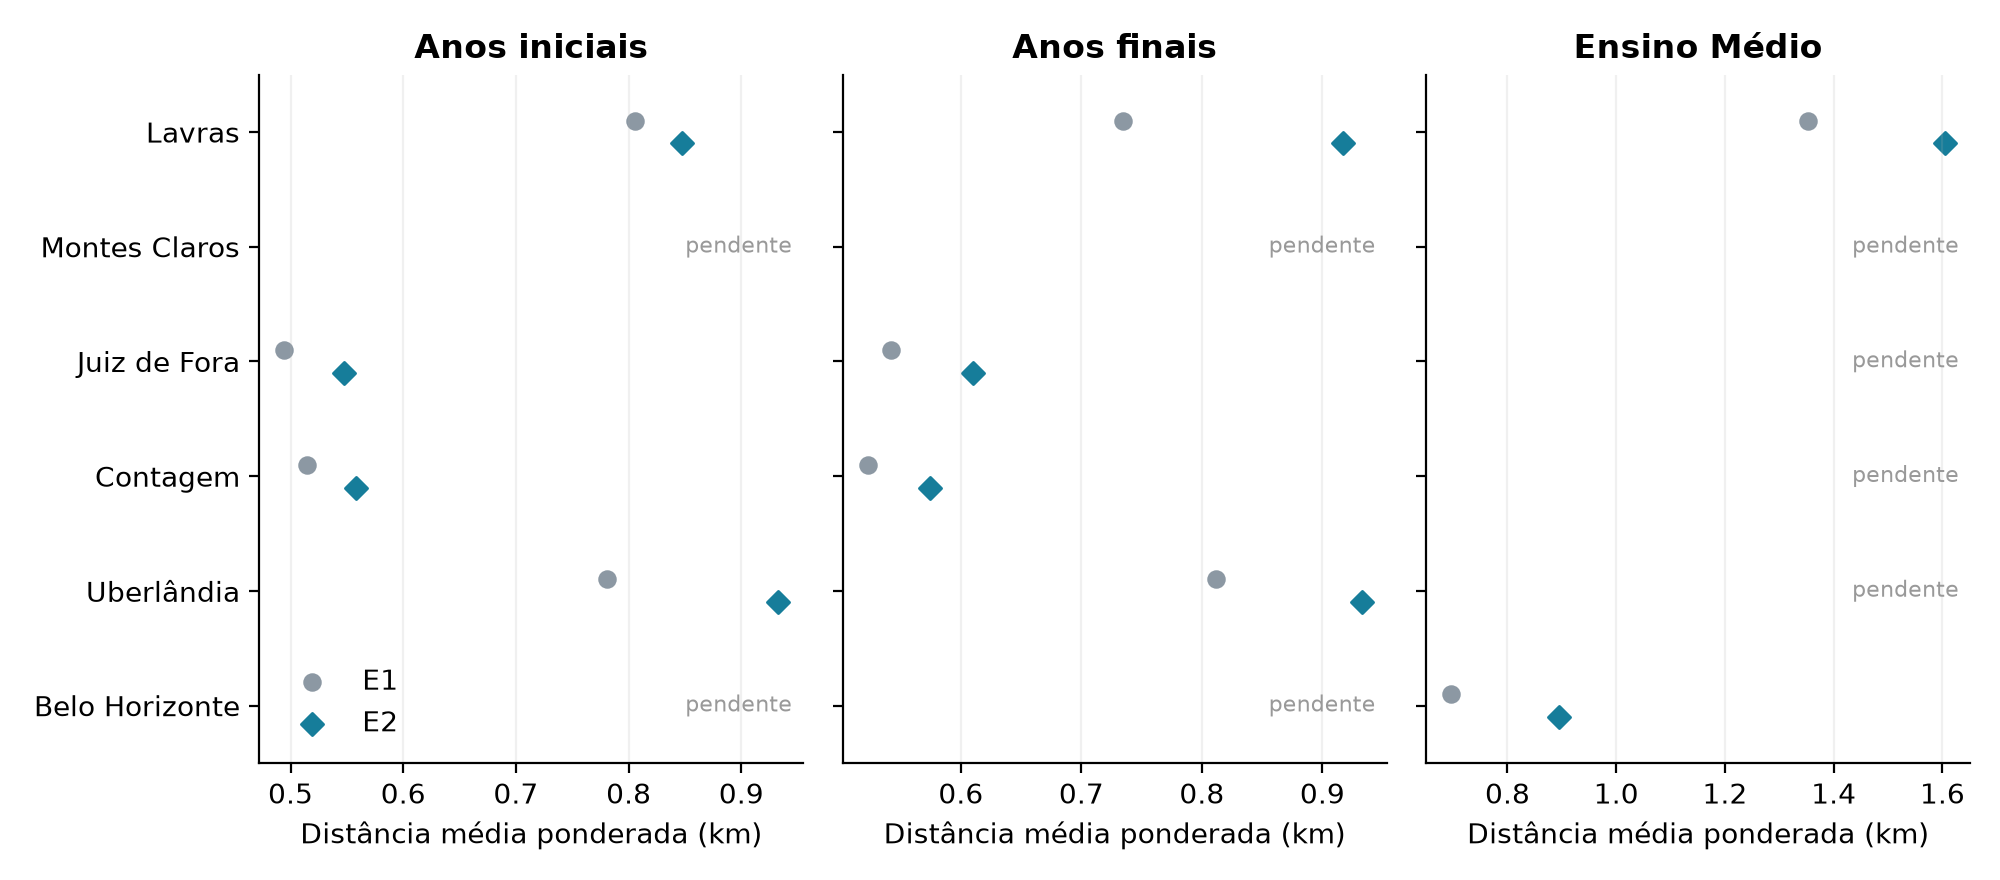

In [3]:
fig,axs=plt.subplots(1,3,figsize=(10,4.4),sharey=True)
for ax,e,title in zip(axs,etapas,titles):
 for i,c in enumerate(cities):
  rows=r.loc[r.municipio.eq(c)&r.etapa.eq(e)]
  for exp,fator,color,marker,dy in [('E1',1,'#8c98a3','o',-.10),('E2',1.25,'#167d9a','D',.10)]:
   row=rows.loc[rows.experimento.eq(exp)&rows.fator.eq(fator)]
   if len(row) and pd.notna(row.iloc[0].distancia_media_km):
    v=row.iloc[0].distancia_media_km;ax.scatter(v,i+dy,c=color,marker=marker,s=32,label=exp if i==0 else None)
   elif exp=='E2':ax.text(.98,i,'pendente',ha='right',va='center',transform=ax.get_yaxis_transform(),color='#999',fontsize=8)
 ax.set_title(title);ax.set_xlabel('Distância média ponderada (km)');ax.grid(axis='x',alpha=.18);ax.set_ylim(5.5,-.5)
axs[0].set_yticks(range(6),cities);axs[0].legend(frameon=False,loc='lower left')
fig.tight_layout();fig.savefig(out/'grandes_distancias.png');
from IPython.display import display, Image
display(Image(filename=str(out/'grandes_distancias.png')))
plt.close(fig)


## Sensibilidade à capacidade

O fator multiplica as matrículas e arredonda para cima. O círculo laranja marca solução sem ótimo comprovado. Nesses casos, o limite de tempo também pode explicar diferenças entre fatores.

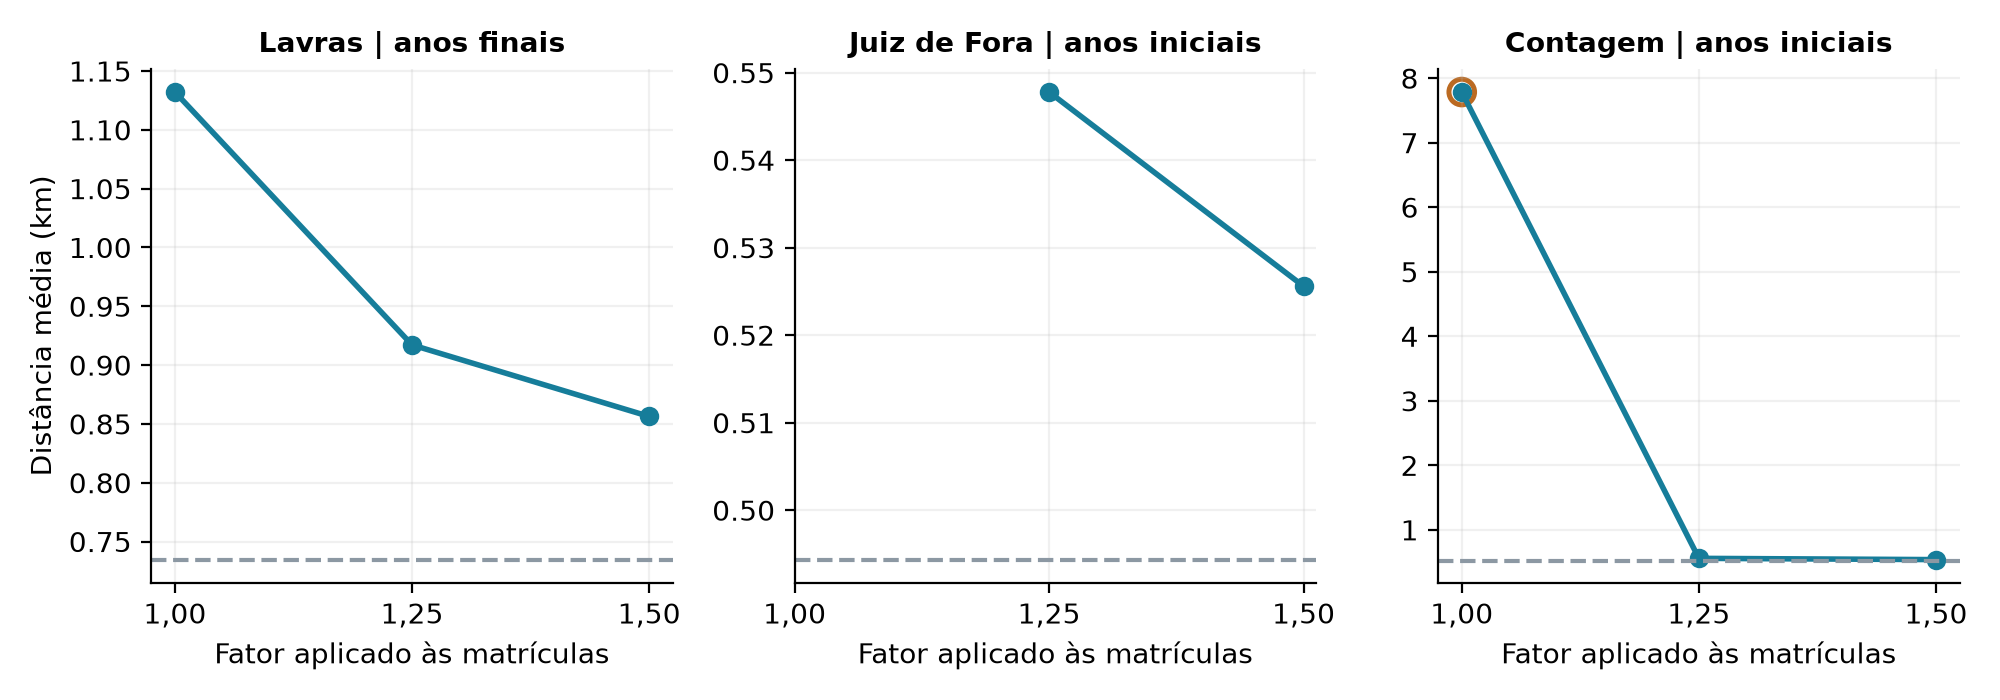

In [4]:
fig,axs=plt.subplots(1,3,figsize=(10,3.5))
for ax,(city,e,title) in zip(axs,[('Lavras',etapas[1],'Lavras | anos finais'),('Juiz de Fora',etapas[0],'Juiz de Fora | anos iniciais'),('Contagem',etapas[0],'Contagem | anos iniciais')]):
 rows=r.loc[r.municipio.eq(city)&r.etapa.eq(e)]
 cap=rows.loc[rows.experimento.eq('E2')&rows.distancia_media_km.notna()].sort_values('fator')
 ax.plot(cap.fator,cap.distancia_media_km,'o-',color='#167d9a',lw=2)
 for row in cap.itertuples():
  if row.status!='OPTIMAL':ax.scatter(row.fator,row.distancia_media_km,s=85,facecolors='none',edgecolors='#bb6a22',lw=1.8)
 base=rows.loc[rows.experimento.eq('E1')]
 if len(base) and pd.notna(base.iloc[0].distancia_media_km):ax.axhline(base.iloc[0].distancia_media_km,ls='--',color='#8c98a3',label='E1')
 ax.set_xticks([1,1.25,1.5],['1,00','1,25','1,50']);ax.set_title(title,fontsize=10);ax.set_xlabel('Fator aplicado às matrículas');ax.grid(alpha=.18)
axs[0].set_ylabel('Distância média (km)');fig.tight_layout();fig.savefig(out/'grandes_capacidades.png');
from IPython.display import display, Image
display(Image(filename=str(out/'grandes_capacidades.png')))
plt.close(fig)


## Esforço computacional

Os eixos são logarítmicos. Contorno preto marca interrupção. Tempo interno do Gurobi e tempo de construção são medidas diferentes. Há uma execução por caso.

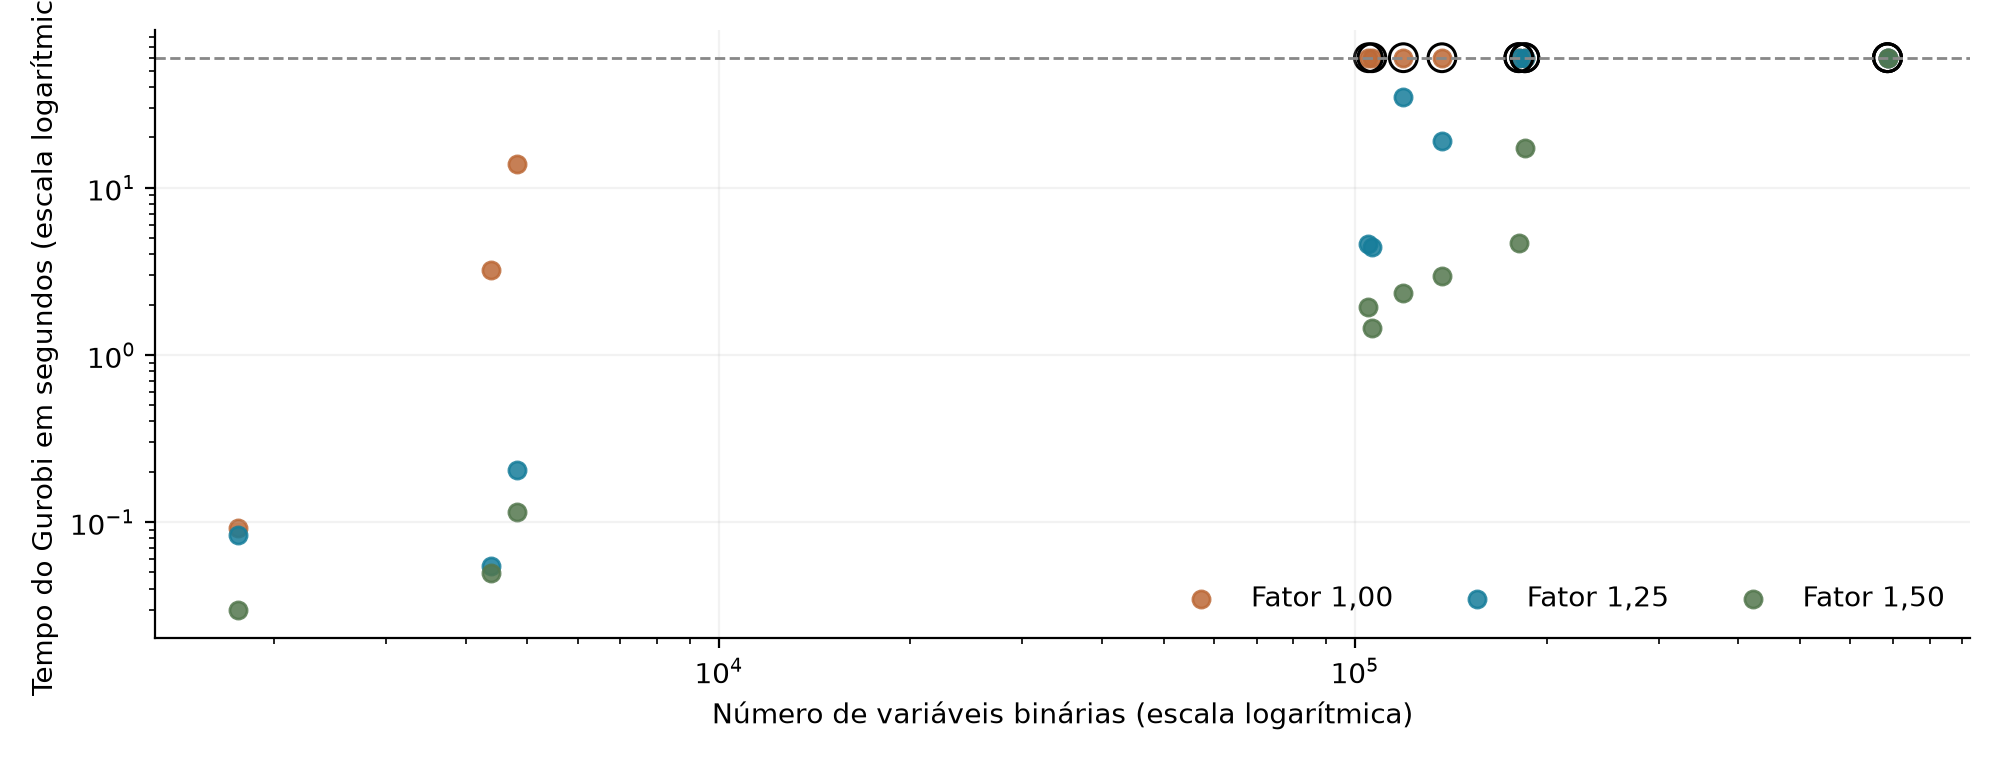

In [5]:
fig,ax=plt.subplots(figsize=(10,3.8))
for factor,col in [(1,'#bc6937'),(1.25,'#167d9a'),(1.5,'#53774d')]:
 a=r.loc[r.experimento.eq('E2')&r.fator.eq(factor)&r.tempo_solver_s.notna()]
 ax.scatter(a.variaveis_previstas,a.tempo_solver_s,c=col,s=38,alpha=.85,label=f'Fator {factor:.2f}'.replace('.',','))
 for row in a.loc[~a.status.eq('OPTIMAL')].itertuples():ax.scatter(row.variaveis_previstas,row.tempo_solver_s,s=100,facecolors='none',edgecolors='black',lw=1.1)
ax.axhline(60,ls='--',color='#888',lw=1);ax.set_xscale('log');ax.set_yscale('log');ax.set_xlabel('Número de variáveis binárias (escala logarítmica)');ax.set_ylabel('Tempo do Gurobi em segundos (escala logarítmica)');ax.legend(frameon=False,ncol=3,loc='lower right');ax.grid(alpha=.16);fig.tight_layout();fig.savefig(out/'grandes_tempos.png');
from IPython.display import display, Image
display(Image(filename=str(out/'grandes_tempos.png')))
plt.close(fig)


## Conferência dos indicadores

A tabela abaixo mantém status e gap junto das distâncias. Atribuições e utilização das escolas estão nas subpastas de resultados.

In [6]:
colunas=['municipio','etapa','experimento','fator','status','distancia_media_km','gap','tempo_solver_s','tempo_construcao_s']
display(r[colunas])


,municipio,etapa,experimento,fator,status,distancia_media_km,gap,tempo_solver_s,tempo_construcao_s
0,Lavras,fundamental_iniciais,E1,1.00,OTIMO_ANALITICO,0.805703,0.000000,NaN,NaN
1,Lavras,fundamental_iniciais,E2,1.00,OPTIMAL,1.007195,0.000000,3.229184,0.017026
2,Lavras,fundamental_iniciais,E2,1.25,OPTIMAL,0.847015,0.000000,0.054474,0.034051
3,Lavras,fundamental_iniciais,E2,1.50,OPTIMAL,0.822106,0.000000,0.049657,0.033656
4,Lavras,fundamental_finais,E1,1.00,OTIMO_ANALITICO,0.734609,0.000000,NaN,NaN
...,...,...,...,...,...,...,...,...,...
67,Belo Horizonte,fundamental_finais,E2,1.50,PENDENTE_COORDENADAS,NaN,NaN,NaN,NaN
68,Belo Horizonte,medio,E1,1.00,OTIMO_ANALITICO,0.696136,0.000000,NaN,NaN
69,Belo Horizonte,medio,E2,1.00,TIME_LIMIT,9.785179,0.854703,60.031345,4.793010
70,Belo Horizonte,medio,E2,1.25,TIME_LIMIT,0.894358,0.000501,60.037136,4.332344
